# **Day 92: Raster Data - Working with a Digital Elevation Model (DEM)**

## **What is Raster Data?**
**Raster data** is a **grid of cells** (pixels), where every cell has a value. A satellite image is raster data, and so is a **DEM**.

A **DEM (Digital Elevation Model)** is a raster where each pixel stores the **height of the ground** above sea level. Popular free DEMs are **SRTM** (30 m) and **Cartosat-1 DEM** from ISRO (30 m).

## **How Does a Raster Know Where it is on Earth?**
A raster is just a table of numbers. To place it on a map, we need **georeferencing** information:
1. The **coordinates of the top-left corner** of the grid.
2. The **pixel size** (for example, 30 m).
3. The **CRS** (for example, UTM zone 45N).

GDAL (the library used by QGIS) stores this as a **geotransform**: `(x_top_left, pixel_width, 0, y_top_left, 0, -pixel_height)`. The pixel height is negative because rows go **down** while northing goes **up**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

## **Making a Synthetic DEM of a Hilly Area**
We make a 30 m DEM of a **made-up** hilly area, shaped a little like the Darjeeling hills: low plains in the south, rising to high ridges in the north.

In [2]:
rows, cols = 200, 200
pixel = 30.0                                     # 30 m pixels (like SRTM)
x_left, y_top = 620000.0, 3000000.0              # Top-left corner in UTM 45N (metres)
geotransform = (x_left, pixel, 0, y_top, 0, -pixel)

r, c = np.mgrid[0:rows, 0:cols]
rng = np.random.default_rng(5)
dem = (150
       + 1900 * np.exp(-(((r - 50) / 45) ** 2 + ((c - 70) / 55) ** 2))       # Main ridge
       + 1200 * np.exp(-(((r - 40) / 30) ** 2 + ((c - 160) / 30) ** 2))      # Second hill
       + 600 * (1 - r / rows)                                                # Land rises to the north
       + rng.normal(0, 8, (rows, cols)))                                     # Small bumps
dem = dem.astype(np.float32)

print("DEM size:", dem.shape, "| pixel:", pixel, "m")
print(f"Lowest: {dem.min():.0f} m, Highest: {dem.max():.0f} m, Mean: {dem.mean():.0f} m")
print(f"Area covered: {rows * pixel / 1000:.1f} km x {cols * pixel / 1000:.1f} km")

DEM size: (200, 200) | pixel: 30.0 m
Lowest: 130 m, Highest: 2518 m, Mean: 868 m
Area covered: 6.0 km x 6.0 km


## **Pixel to Coordinate and Coordinate to Pixel**
These two small functions are the heart of raster GIS. Every time you click on a raster in QGIS and see a value, this calculation happens.

In [3]:
def pixel_to_coord(row, col, gt=geotransform):
    """Centre of a pixel -> (x, y) in map units."""
    x = gt[0] + (col + 0.5) * gt[1]
    y = gt[3] + (row + 0.5) * gt[5]
    return x, y

def coord_to_pixel(x, y, gt=geotransform):
    """(x, y) in map units -> (row, col) of the pixel that contains it."""
    col = int((x - gt[0]) / gt[1])
    row = int((y - gt[3]) / gt[5])
    return row, col

print("Centre of pixel (0, 0):", pixel_to_coord(0, 0))
print("Centre of pixel (100, 50):", pixel_to_coord(100, 50))

x, y = 623500, 2997500
row, col = coord_to_pixel(x, y)
print(f"Point ({x}, {y}) is in pixel row {row}, col {col}, height = {dem[row, col]:.0f} m")

Centre of pixel (0, 0): (620015.0, 2999985.0)
Centre of pixel (100, 50): (621515.0, 2996985.0)
Point (623500, 2997500) is in pixel row 83, col 116, height = 1079 m


## **Slope and Aspect**
- **Slope:** How **steep** the ground is (in degrees). Flat = 0°.
- **Aspect:** Which **direction** the slope faces (North, East, South, West). In the hills, south-facing slopes get more sunlight.

We calculate them from how fast the height changes in the x and y directions. `np.gradient()` gives these changes.

In [4]:
dz_dy, dz_dx = np.gradient(dem, pixel)            # Change in height per metre (rows, then columns)
slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
aspect = (np.degrees(np.arctan2(-dz_dx, dz_dy)) + 360) % 360      # 0 = North, 90 = East ...

print(f"Mean slope: {slope.mean():.1f}°, Steepest: {slope.max():.1f}°")
print(f"Pixels steeper than 30° (landslide risk): {(slope > 30).mean():.1%}")

Mean slope: 27.9°, Steepest: 62.8°
Pixels steeper than 30° (landslide risk): 44.7%


Slopes steeper than about 30° are more likely to have **landslides**, especially in the monsoon. This kind of map is used for **landslide risk mapping** in the Darjeeling hills.

## **Hillshade: Making the DEM Look 3D**
A **hillshade** imagines the Sun shining from one direction (usually from the north-west) and shades the slopes. It makes terrain easy to understand.

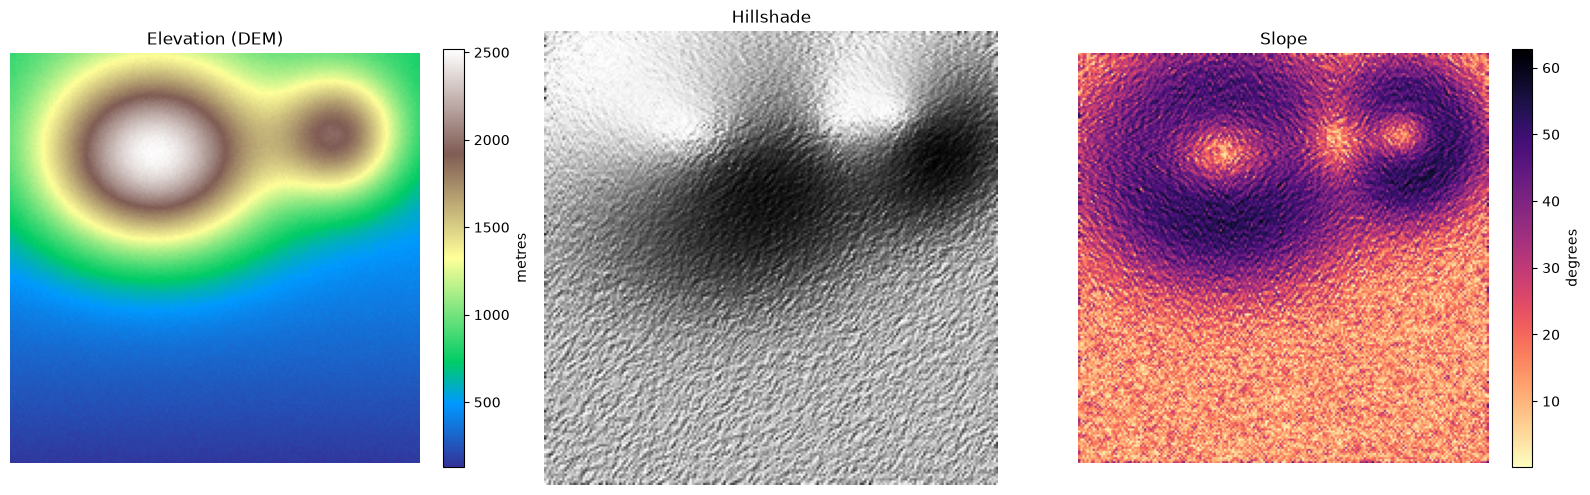

In [5]:
ls = LightSource(azdeg=315, altdeg=45)
hillshade = ls.hillshade(dem, vert_exag=2, dx=pixel, dy=pixel)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(dem, cmap="terrain")
fig.colorbar(im0, ax=axes[0], fraction=0.046, label="metres")
axes[0].set_title("Elevation (DEM)")

axes[1].imshow(hillshade, cmap="gray")
axes[1].set_title("Hillshade")

im2 = axes[2].imshow(slope, cmap="magma_r")
fig.colorbar(im2, ax=axes[2], fraction=0.046, label="degrees")
axes[2].set_title("Slope")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Contour Lines**
**Contour lines** join points of the **same height**. They are used on every topographic map (like Survey of India toposheets).

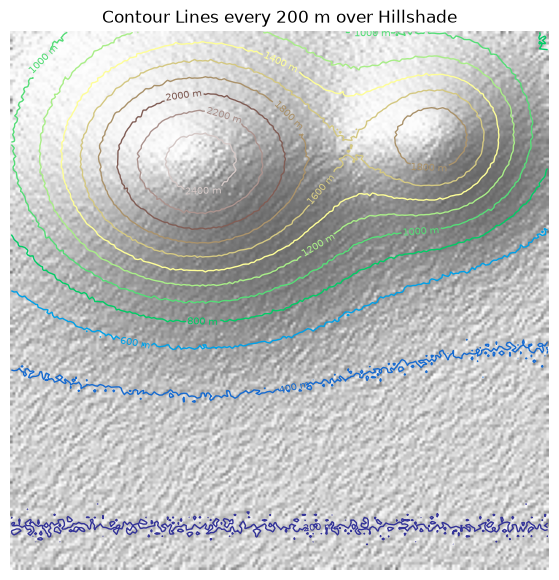

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(hillshade, cmap="gray", alpha=0.6)
levels = np.arange(200, 2800, 200)
cs = ax.contour(dem, levels=levels, cmap="terrain", linewidths=1)
ax.clabel(cs, fmt="%d m", fontsize=7)
ax.set_title("Contour Lines every 200 m over Hillshade")
ax.axis("off")
plt.show()

## **Reclassifying: Elevation Zones**
**Reclassification** means changing ranges of values into classes. Let us divide the land into height zones.

In [7]:
zones = np.digitize(dem, bins=[300, 1000, 2000])      # 0: <300, 1: 300-1000, 2: 1000-2000, 3: >2000
names = ["Plains (<300 m)", "Foothills (300-1000 m)", "Hills (1000-2000 m)", "High hills (>2000 m)"]
pixel_area_km2 = pixel * pixel / 1e6

for i, name in enumerate(names):
    n = (zones == i).sum()
    print(f"{name:<24}{n:>7} pixels  {n * pixel_area_km2:>6.1f} km²  {n / zones.size:6.1%}")

Plains (<300 m)            9585 pixels     8.6 km²   24.0%
Foothills (300-1000 m)    14972 pixels    13.5 km²   37.4%
Hills (1000-2000 m)       13012 pixels    11.7 km²   32.5%
High hills (>2000 m)       2431 pixels     2.2 km²    6.1%


## **Zonal Statistics**
What is the average slope in each elevation zone?

In [8]:
for i, name in enumerate(names):
    mask = zones == i
    print(f"{name:<24} mean slope {slope[mask].mean():5.1f}°   max {slope[mask].max():5.1f}°")

Plains (<300 m)          mean slope  14.1°   max  51.4°
Foothills (300-1000 m)   mean slope  22.9°   max  59.5°
Hills (1000-2000 m)      mean slope  41.8°   max  62.8°
High hills (>2000 m)     mean slope  37.8°   max  59.8°


## **NoData Values**
Real DEMs often have missing areas (for example, in deep valleys where the satellite could not see). These are stored with a **NoData** value like -9999.

In [9]:
dem_with_gaps = dem.copy()
dem_with_gaps[150:160, 20:40] = -9999
nodata = -9999
valid = dem_with_gaps[dem_with_gaps != nodata]
print("Wrong mean (including -9999):", round(dem_with_gaps.mean(), 1))
print("Correct mean (without NoData):", round(valid.mean(), 1))

Wrong mean (including -9999): 816.2
Correct mean (without NoData): 870.6


## **Saving the DEM as an ESRI ASCII Grid (.asc)**
The **ASCII grid** is a simple text raster format. QGIS can open it directly. It has a small header with the georeferencing, and then the pixel values row by row.

In [10]:
def write_ascii_grid(path, array, x_left, y_bottom, cell, nodata=-9999):
    rows, cols = array.shape
    with open(path, "w") as f:
        f.write(f"ncols {cols}\nnrows {rows}\n")
        f.write(f"xllcorner {x_left}\nyllcorner {y_bottom}\n")
        f.write(f"cellsize {cell}\nNODATA_value {nodata}\n")
        for row in array:
            f.write(" ".join(f"{v:.1f}" for v in row) + "\n")

y_bottom = y_top - rows * pixel
write_ascii_grid("hills_dem.asc", dem, x_left, y_bottom, pixel)

with open("hills_dem.asc") as f:
    for _ in range(7):
        print(f.readline().rstrip()[:80])

ncols 200
nrows 200
xllcorner 620000.0
yllcorner 2994000.0
cellsize 30.0
NODATA_value -9999
853.0 854.0 867.9 878.7 890.1 887.7 888.3 892.6 911.1 924.7 920.3 915.0 924.1 95


To open it in QGIS: **Layer -> Add Layer -> Add Raster Layer**, choose `hills_dem.asc`, and set its CRS to **EPSG:32645**.

In [11]:
# Quick question
# A DEM has 30 m pixels. How many square metres does one pixel cover?